<!-- m6:clase=3;checkpoints=7;preguntas=3 -->
# Módulo 6 · Clase 3 — Inferencia bayesiana con PyMC, redes bayesianas y simulador de fraude
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · viernes 13-11-2026 · 18:30–21:30

**Cómo trabajar este cuaderno**
1. Ejecute las celdas en orden con `Shift + Enter`. Las celdas de demostración ya están completas.
2. En cada **✏️ Checkpoint** complete los `___` y ejecute: si está bien, aparece ✅ y un código personal.
3. Responda las **💬 Preguntas** en 2 o 3 líneas.
4. Al final: **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta `talleres/clase3.ipynb` → mensaje `Clase 3`.

> Datos: app de pagos móviles **PagoYa** (ficticia, simulada con fines didácticos).

## 0. Preparación y registro (Checkpoint 0)

In [1]:
import importlib, subprocess, sys                            # instala lo que falte (solo la primera vez, ~30 s)
for paquete in ['pymc', 'pgmpy']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
print('Paquetes listos')

Paquetes listos


In [2]:
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):                          # funciones del curso (incluye el simulador de la app)
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm                                           # programación probabilística (MCMC)
logging.getLogger('pymc').setLevel(logging.ERROR)          # menos mensajes en pantalla
from sklearn.model_selection import train_test_split
plt.rcParams['figure.figsize'] = (10, 3.4)
sigmoide = lambda z: 1 / (1 + np.exp(-z))                    # de log-odds a probabilidad
print('Listo · curso', curso.VERSION, '· PyMC', pm.__version__)

Listo · curso m6-2026.11 · PyMC 5.28.5


### ✏️ Checkpoint 0 · ⏱ 2 min
Registre su nombre como **'Apellido Nombre'** e indique la **clase 3**.

In [3]:
curso.registrar('Villamarin Kevin', clase=3)          # ✏️ su apellido y nombre, y el número de esta clase

Estudiante registrado: Villamarin Kevin
Clase 3
✅ Checkpoint 0 correcto · código K0-389B


In [4]:
df = curso.cargar_pagoya_limpio()                           # mismos datos y limpieza de las clases 1 y 2
df['ratio'] = df['monto'] / df['ingreso_mensual']            # monto relativo al ingreso del usuario
imb = df[df['provincia'] == 'Imbabura']
k, n = int(imb['fraude'].sum()), len(imb)                    # 3 fraudes en 130 transacciones
print(f'Imbabura: {k} fraudes en {n} transacciones')

Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 8.44%
Imbabura: 3 fraudes en 130 transacciones


---
## 3.1 Inferencia bayesiana computacional con PyMC
Ayer la posterior de la tasa de Imbabura tenía **fórmula cerrada** (Beta). En casi todos los modelos reales no la hay: se obtienen **muestras** de la posterior con **MCMC** (cadenas de Markov Monte Carlo). PyMC usa el algoritmo **NUTS**. Primero lo comprobamos con el caso conocido.

### ✏️ Checkpoint 1 · ⏱ 6 min
Escriba el modelo beta-binomial en PyMC: prior **Beta(2, 20)** y verosimilitud **Binomial(n, tasa)** con `observed=k`. Obtenga la **media posterior**.

In [5]:
with pm.Model() as modelo_tasa:
    tasa = pm.Beta('tasa', alpha=2, beta=20)                    # ✏️ prior
    pm.Binomial('obs', n=n, p=tasa, observed=k)                 # ✏️ verosimilitud
    tr_tasa = pm.sample(1000, tune=1000, chains=2, random_seed=42, progressbar=False)
media_mcmc = float(tr_tasa.posterior['tasa'].mean())
print(f'MCMC: {media_mcmc:.4f} · fórmula exacta (a+k)/(a+b+n): {(2 + k) / (22 + n):.4f}')
curso.checkpoint(1, media_mcmc)

MCMC: 0.0331 · fórmula exacta (a+k)/(a+b+n): 0.0329
✅ Checkpoint 1 correcto · código K1-66C5


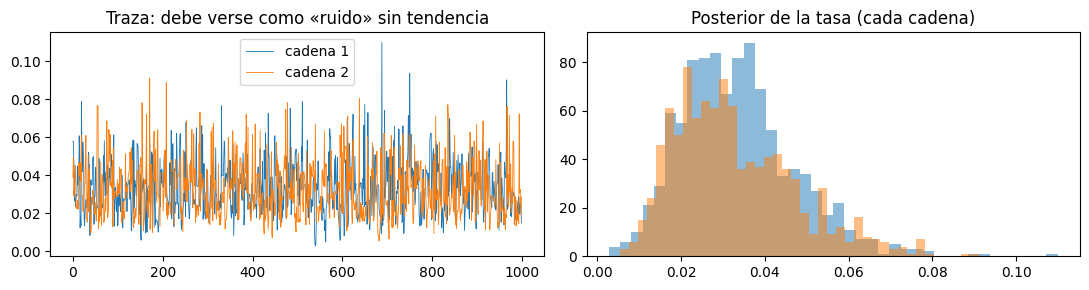

,media,desv,ic_3%,ic_97%,r_hat,ess
tasa,0.0331,0.0141,0.0124,0.0636,1.0001,840.8111


In [6]:
x = tr_tasa.posterior['tasa'].values                         # matriz cadenas × muestras
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for c in range(x.shape[0]):
    ax[0].plot(x[c], lw=0.6, label=f'cadena {c + 1}'); ax[1].hist(x[c], bins=40, alpha=0.5)
ax[0].set_title('Traza: debe verse como «ruido» sin tendencia'); ax[0].legend()
ax[1].set_title('Posterior de la tasa (cada cadena)'); plt.tight_layout(); plt.show()
curso.diagnostico(tr_tasa, ['tasa'])

---
## 3.2 Redes bayesianas con pgmpy
Una **red bayesiana** es un grafo dirigido: cada nodo es una variable y cada flecha, una dependencia directa. Cada nodo tiene una **tabla de probabilidad condicional** (CPT) dada por sus padres. Ejemplo de **riesgo de impago** de un usuario de PagoYa con microcrédito:

`Desempleo → Mora ← IngresoBajo`, `Mora → Default`, `Desempleo → Default`

In [7]:
try:
    from pgmpy.models import DiscreteBayesianNetwork as RedBayesiana   # pgmpy ≥ 1.0
except ImportError:
    from pgmpy.models import BayesianNetwork as RedBayesiana           # versiones anteriores
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

red = RedBayesiana([('Desempleo', 'Mora'), ('IngresoBajo', 'Mora'), ('Mora', 'Default'), ('Desempleo', 'Default')])
cpd_d = TabularCPD('Desempleo', 2, [[0.92], [0.08]])                  # P(Desempleo = 1) = 8 %
cpd_i = TabularCPD('IngresoBajo', 2, [[0.70], [0.30]])                # P(IngresoBajo = 1) = 30 %
cpd_m = TabularCPD('Mora', 2, [[0.95, 0.80, 0.70, 0.45],              # P(Mora | Desempleo, IngresoBajo)
                               [0.05, 0.20, 0.30, 0.55]], evidence=['Desempleo', 'IngresoBajo'], evidence_card=[2, 2])
cpd_f = TabularCPD('Default', 2, [[0.98, 0.85, 0.90, 0.60],           # P(Default | Mora, Desempleo)
                                  [0.02, 0.15, 0.10, 0.40]], evidence=['Mora', 'Desempleo'], evidence_card=[2, 2])
red.add_cpds(cpd_d, cpd_i, cpd_m, cpd_f)
print('Modelo válido:', red.check_model())
inferencia = VariableElimination(red)                                 # inferencia exacta
print('P(Default = 1) sin evidencia:', round(inferencia.query(['Default']).values[1], 4))

Modelo válido: True
P(Default = 1) sin evidencia: 0.0449


### ✏️ Checkpoint 2 · ⏱ 4 min
Calcule **P(Default = 1 | Mora = 1)**: la probabilidad de impago de un cliente que ya está en mora.

In [11]:
p_default_mora = inferencia.query(['Default'], evidence={'Mora':1}).values[1]   # ✏️
print(f'P(Default | Mora) = {p_default_mora:.4f}')
curso.checkpoint(2, p_default_mora)

P(Default | Mora) = 0.1767
✅ Checkpoint 2 correcto · código K2-A23A


In [12]:
casos = {'Mora': {'Mora': 1}, 'Mora + ingreso bajo': {'Mora': 1, 'IngresoBajo': 1}, 'Mora + desempleo': {'Mora': 1, 'Desempleo': 1}}
for nombre, ev in casos.items():                               # razonamiento PREDICTIVO (causas → efecto)
    print(f'P(Default | {nombre:<20}) = {inferencia.query(["Default"], evidence=ev).values[1]:.3f}')
print(f'P(Desempleo | Default) = {inferencia.query(["Desempleo"], evidence={"Default": 1}).values[1]:.3f}  ← razonamiento DIAGNÓSTICO')

P(Default | Mora                ) = 0.177
P(Default | Mora + ingreso bajo ) = 0.158
P(Default | Mora + desempleo    ) = 0.400
P(Desempleo | Default) = 0.434  ← razonamiento DIAGNÓSTICO


### 💬 Pregunta 2
Con mora, P(Default) = 0,177; si además sabemos que el ingreso es bajo, baja a 0,158. ¿Por qué más información «mala» reduce el riesgo?

**Respuesta:**
Añadir el ingreso bajo no suma riesgo nuevo porque la mora ya "contenía" parte de esa información: los clientes en mora suelen tener ingresos bajos. Al confirmar ambas señales, el riesgo no se duplica; se reparte entre las dos causas.

---
## 3.3 Regresión logística bayesiana y modelo jerárquico
**Regresión logística bayesiana**: log-odds(fraude) = a + b · X, con **priors** sobre a y b. El resultado no es un coeficiente sino una **distribución** para cada uno.

In [13]:
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3, stratify=df['fraude'], random_state=42)
media, desv = X_train.mean(), X_train.std()                  # estandarizar con datos de ENTRENAMIENTO
Z = ((X_train - media) / desv).values
with pm.Model() as modelo_log:
    a = pm.Normal('a', mu=0, sigma=2)                         # prior del intercepto
    b = pm.Normal('b', mu=0, sigma=1, shape=len(cols))        # priors de los coeficientes (regularizan)
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(Z, b), observed=y_train.values)
    tr_log = pm.sample(1000, tune=1000, chains=2, random_seed=42, progressbar=False)
diag = curso.diagnostico(tr_log, ['a', 'b']); diag.index = ['intercepto'] + cols
diag['odds_ratio'] = np.exp(diag['media']).round(2)           # efecto de +1 desviación estándar
diag

,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio
intercepto,-3.4305,0.1473,-3.7059,-3.1690,1.0007,1112.1984,0.03
dispositivo_nuevo,1.0003,0.0747,0.8609,1.1388,0.9994,1365.4942,2.72
distancia_km,0.5420,0.0784,0.3948,0.6915,0.9993,1825.0914,1.72
ratio,0.8881,0.0806,0.7409,1.0417,1.0002,1322.4489,2.43
intentos_pin,0.6119,0.0758,0.4735,0.7542,1.0004,1527.3231,1.84


### ✏️ Checkpoint 3 · ⏱ 4 min
Obtenga la **media posterior del coeficiente de `dispositivo_nuevo`** (es el primer elemento de `b`).

In [14]:
coef_disp = float(tr_log.posterior['b'].values[..., 0].mean())   # ✏️ b[0]
print(f'Coeficiente dispositivo_nuevo: {coef_disp:.3f} · odds ratio {np.exp(coef_disp):.2f}')
curso.checkpoint(3, coef_disp)

Coeficiente dispositivo_nuevo: 1.000 · odds ratio 2.72
✅ Checkpoint 3 correcto · código K3-00B4


**Modelo jerárquico por provincia.** Cada provincia tiene su intercepto, pero todos salen de una **distribución común** cuya media y dispersión también se estiman: las provincias con pocos datos «toman prestada» información de las demás (*partial pooling*). Usamos la forma **no centrada** (`a = μ + σ · z`), que evita problemas del muestreador.

In [15]:
provincias = df['provincia'].astype('category')
idx, nombres = provincias.cat.codes.values, list(provincias.cat.categories)
with pm.Model() as modelo_jer:
    mu = pm.Normal('mu', mu=-2.4, sigma=1)                    # log-odds nacional (≈ 8 %)
    sigma = pm.HalfNormal('sigma', sigma=0.5)                 # cuánto difieren las provincias
    z = pm.Normal('z', 0, 1, shape=len(nombres))              # forma NO centrada
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)
    pm.Bernoulli('obs', logit_p=a_prov[idx], observed=df['fraude'].values)
    tr_jer = pm.sample(1000, tune=1500, chains=2, random_seed=42, target_accept=0.99, progressbar=False)
tasas = sigmoide(tr_jer.posterior['a_prov'].values).reshape(-1, len(nombres))
tabla = pd.DataFrame({'n': df.groupby('provincia').size(), 'tasa_observada': df.groupby('provincia')['fraude'].mean(),
                      'tasa_jerarquica': pd.Series(tasas.mean(0), index=nombres)}).round(4)
tabla

,n,tasa_observada,tasa_jerarquica
Azuay,320,0.1062,0.0917
El Oro,236,0.0890,0.0851
Guayas,781,0.0883,0.0861
Imbabura,130,0.0231,0.0706
Loja,213,0.1033,0.0893
Manabí,311,0.0707,0.0788
Pichincha,844,0.0841,0.0839
Tungurahua,161,0.0683,0.0795


### ✏️ Checkpoint 4 · ⏱ 5 min
Obtenga la **tasa jerárquica de Imbabura** (media posterior) de la tabla.

In [19]:
tasa_imb = tabla.loc['Imbabura', 'tasa_jerarquica']          # ✏️
print(f'Imbabura: observada {tabla.loc["Imbabura", "tasa_observada"]:.1%} · beta-binomial 3,3 % · jerárquica {tasa_imb:.1%}')
curso.checkpoint(4, tasa_imb)

Imbabura: observada 2.3% · beta-binomial 3,3 % · jerárquica 7.1%
✅ Checkpoint 4 correcto · código K4-8EB2


### 💬 Pregunta 1
¿Qué indican un R-hat ≤ 1,01 y un ESS alto? ¿Qué haría si PyMC reporta divergencias o R-hat de 1,05?

**Respuesta:**

**R-hat ≤ 1,01 y ESS alto:** Indican que las cadenas convergieron correctamente. Tus estimaciones son fiables y estables.

**Si hay R-hat = 1,05 o divergencias:** La muestra no es fiable (el muestreador no exploró bien la distribución).

---
## 3.4 Aplicación: riesgo con incertidumbre y simulador de la app
Con las muestras de la posterior, cada transacción no recibe **un** puntaje sino **una distribución** de probabilidades de fraude.

In [20]:
a_s = tr_log.posterior['a'].values.reshape(-1)               # 2000 muestras del intercepto
b_s = tr_log.posterior['b'].values.reshape(-1, len(cols))    # 2000 × 4 muestras de coeficientes
def prob_fraude(t):
    z = (np.array([t[c] for c in cols]) - media.values) / desv.values   # misma estandarización
    return sigmoide(a_s + b_s @ z)                           # 2000 probabilidades (una por muestra)

**Personalice su app.** Elija un **nombre** (no «PagoYa») y dos **colores hex** distintos con el formato `#RRGGBB` (el ejemplo `#7B2CBF` no se acepta: elija los suyos). Puede buscarlos en Google con «color picker».

### ✏️ Checkpoint 5 · ⏱ 3 min
Defina `nombre_app`, `color_principal` y `color_alerta` y valide su personalización.

In [38]:
nombre_app, color_principal, color_alerta = 'CheckPay', '#1F4976', '#D62728'   # ✏️ su app
curso.checkpoint(5, (nombre_app, color_principal, color_alerta))

Huella UI: CheckPay · #1F4976 · #D62728
✅ Checkpoint 5 correcto · código K5-0FE4


### ✏️ Checkpoint 6 · ⏱ 4 min
Calcule la **probabilidad media de fraude** de esta transacción: dispositivo nuevo, a 10 km, ratio 0,15 (USD 135 con ingreso de USD 900) y 1 intento de PIN.

Media 43.5% · intervalo creíble 90 %: 37.0% – 50.0%
✅ Checkpoint 6 correcto · código K6-FBC9


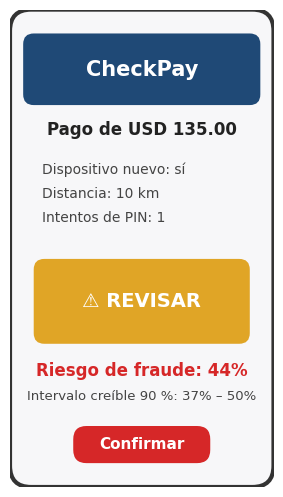

In [39]:
transaccion = {'dispositivo_nuevo': 1, 'distancia_km': 10, 'ratio': 0.15, 'intentos_pin': 1, 'monto': 135}
probs = prob_fraude(transaccion)                              # ✏️ distribución de probabilidades
print(f'Media {probs.mean():.1%} · intervalo creíble 90 %: {np.percentile(probs, 5):.1%} – {np.percentile(probs, 95):.1%}')
curso.checkpoint(6, probs.mean())
curso.pantalla_app(nombre_app, color_principal, color_alerta, transaccion, probs)

**Simulador interactivo**: mueva los controles. ¿Puede lograr que una transacción con dispositivo nuevo pase como «APROBADA»? ¿Qué pasa con el intervalo cuando lleva las variables a valores extremos?

In [40]:
curso.simulador(prob_fraude, nombre_app, color_principal, color_alerta)   # interactivo (solo en Colab)

### 💬 Pregunta 3
Para la transacción del Checkpoint 6, ¿qué decisión tomaría y por qué importa el intervalo creíble, no solo la media?

**Respuesta:** Revisión manual

Un 43,5% es demasiado alto para aprobar automáticamente, pero no es una certeza (>50%) como para bloquear de forma definitiva.

¿Por qué importa el intervalo creíble [37% – 50%]?

Porque la media sola puede engañar. El intervalo te dice que, incluso en el mejor de los escenarios (37%), el riesgo sigue siendo alto. Además, cruza el umbral del 50%, lo que demuestra que la incertidumbre es real y obliga a ser conservador. La media es un solo número; el intervalo demuestra que la decisión de ser cauteloso es robusta.

---
## Deber (20 pts · individual · ≈ 3 horas)
Abra el enlace **«Deber M6»** del aula virtual. Cada estudiante recibe **datos personalizados** según su nombre. Entrega: **Archivo → Guardar (Ctrl+S)** → su repositorio → ruta `deber/deber.ipynb`. **Plazo: domingo 15-nov-2026, 11:00.**

---
## Cierre de la clase

In [41]:
curso.resumen(total=7)                                      # avance de checkpoints

Estudiante: Villamarin Kevin · checkpoints correctos: 7/7
Pendientes: ninguno ✅
👉 Responda las preguntas 💬 y guarde: Archivo → Guardar (Ctrl+S) → su repositorio (hasta las 12:00 del día siguiente sin descuento).


**Para terminar:** revise los ✅ y las 3 preguntas 💬 → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* **el suyo** → ruta `talleres/clase3.ipynb` → mensaje `Clase 3`.